In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Environment ready ✅")

Environment ready ✅


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your final dataset (from autoencoder step)
df = pd.read_csv("df_model_with_ae.csv")

print(df.shape)
df.head()

(130715, 3)


,reconstruction_error,true_label,ae_anomaly
0,0.001654,0,0
1,0.001656,0,0
2,9.142499,0,0
3,0.001654,0,0
4,0.001656,0,0


In [4]:
df_ae = pd.read_csv("df_model_with_ae.csv")

print("AE shape:", df_ae.shape)

AE shape: (130715, 3)


In [5]:
# Sample 20k rows safely
sample_idx = df_ae.sample(n=20000, random_state=42).index

In [6]:
def load_sampled_csv(file_path, sample_idx):
    return pd.read_csv(
        file_path,
        skiprows=lambda x: x not in sample_idx and x != 0
    )

In [7]:
df_normal = load_sampled_csv("df_normal_processed.csv", sample_idx)
df_ddos   = load_sampled_csv("df_ddos_processed.csv", sample_idx)

In [8]:
df_features = pd.concat([df_normal, df_ddos], ignore_index=True)

In [9]:
# Load small chunks (safe)
df_normal = pd.read_csv("df_normal_processed.csv", nrows=10000)
df_ddos   = pd.read_csv("df_ddos_processed.csv", nrows=10000)

# Combine
df_features = pd.concat([df_normal, df_ddos], ignore_index=True)

# Load AE results
df_ae = pd.read_csv("df_model_with_ae.csv")

# MATCH LENGTHS (IMPORTANT FIX)
min_len = min(len(df_features), len(df_ae))

df_sample = df_features.iloc[:min_len].copy()
df_sample['ae_anomaly'] = df_ae['ae_anomaly'].iloc[:min_len].values

print(df_sample.shape)

(17179, 776)


In [10]:
df_normal = df_sample[df_sample['ae_anomaly'] == 0]
df_anomaly = df_sample[df_sample['ae_anomaly'] == 1]

print("Normal:", len(df_normal))
print("Anomaly:", len(df_anomaly))

Normal: 16624
Anomaly: 555


In [11]:
feature_cols = df_sample.drop(columns=['ae_anomaly']).columns

feature_cols = df_sample.drop(columns=['ae_anomaly', 'ts']).columns

feature_diff = {}

for col in feature_cols:
    try:
        diff = abs(df_anomaly[col].mean() - df_normal[col].mean())
        feature_diff[col] = diff
    except:
        continue

# Sort features
feature_importance = pd.Series(feature_diff).sort_values(ascending=False)

# Top 10 features
top_features = feature_importance.head(10)
print(top_features)

conn_state_SH       44.150630
history_F           43.826733
history_S            5.494339
history_ShADadfF     2.926886
history_Dd           2.656574
conn_state_SF        2.128596
proto_tcp            1.251319
proto_udp            1.230674
service_dns          1.226227
service_http         1.019856
dtype: float64


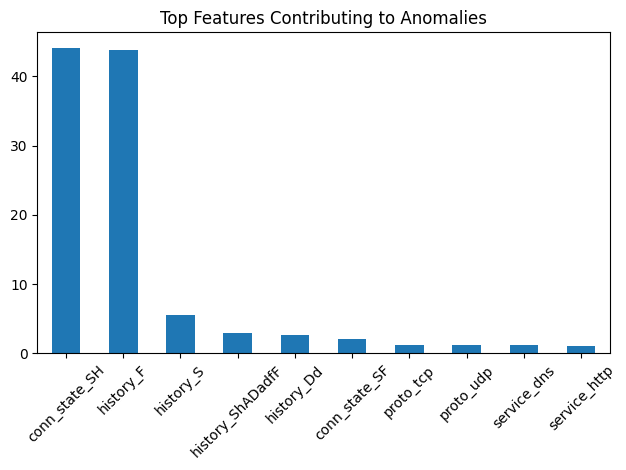

In [12]:
plt.figure()
top_features.plot(kind='bar')
plt.title("Top Features Contributing to Anomalies")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("feature_importance.png")
plt.show()

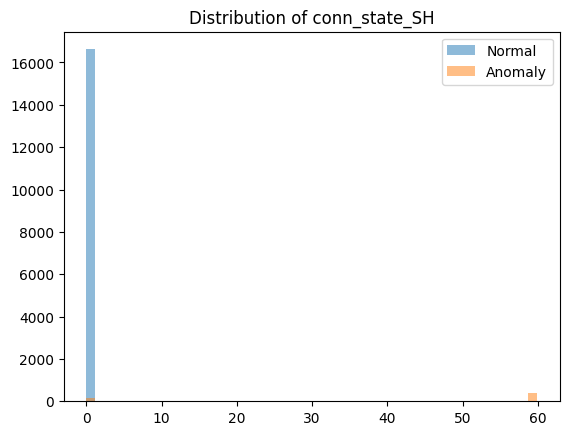

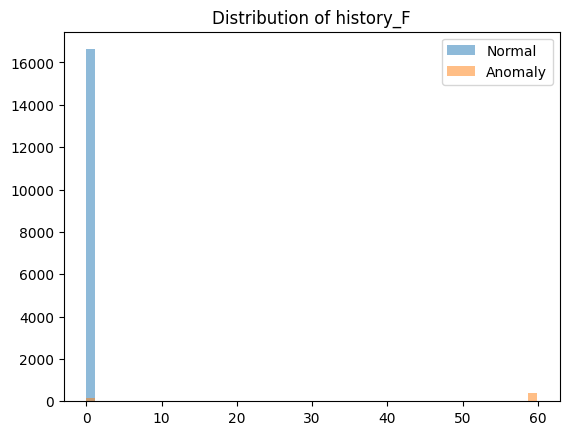

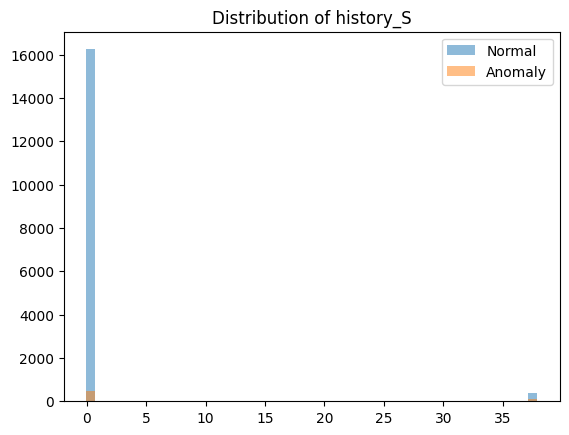

In [13]:
important_features = top_features.index[:3]

for col in important_features:
    plt.figure()

    plt.hist(df_normal[col], bins=50, alpha=0.5, label='Normal')
    plt.hist(df_anomaly[col], bins=50, alpha=0.5, label='Anomaly')

    plt.title(f"Distribution of {col}")
    plt.legend()

    plt.savefig(f"{col}_distribution.png")
    plt.show()

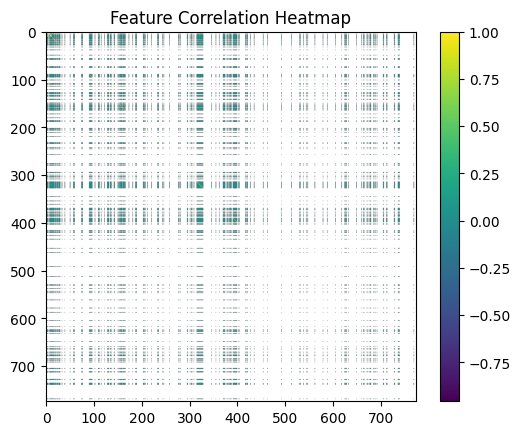

In [14]:
# Only numeric features
df_corr = df_sample[feature_cols].select_dtypes(include=[np.number])

corr = df_corr.corr()

plt.figure()
plt.imshow(corr)
plt.colorbar()
plt.title("Feature Correlation Heatmap")

plt.savefig("correlation_heatmap.png")
plt.show()

In [15]:
feature_importance.to_csv("feature_importance.csv")

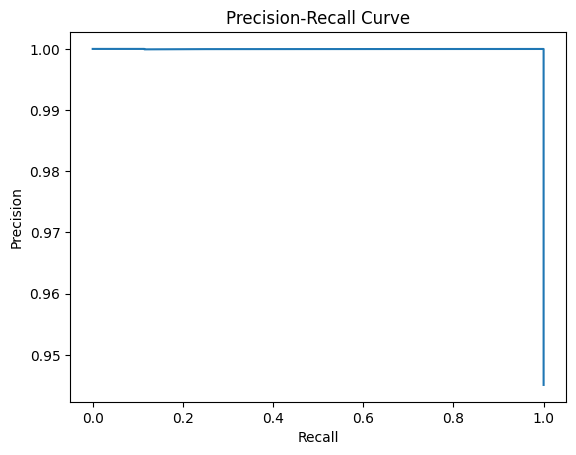

In [16]:
from sklearn.metrics import precision_recall_curve

y_true = df_ae['true_label']
scores = df_ae['reconstruction_error']

precision, recall, thresholds = precision_recall_curve(y_true, scores)

plt.figure()
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.savefig("precision_recall_curve.png")
plt.show()